# My Question: What is the probability that an algorithm scores between 310 and 410 points in a random Breakout game?

# Description:
## The random variable (X) that I am simulating are scores that an AI could potentially get in a game of Breakout.
## I am using a normal model to approximate a discrete distribution.
## One trial would be a random game of Breakout that an algorithm plays. Some potential outcomes would be values between a score of 310 and a score of 410.

In [6]:
!pip install gymnasium
!pip install "gymnasium[atari]"
!pip install ale-py
!pip install autorom[accept-rom-license]

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


# RESTART YOUR KERNEL AND THEN RUN THE REST OF THE PROGRAM.
# DO NOT PERFORM THE INSTALLATIONS AGAIN

In [1]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v1             CliffWalkingSlippery-v1
FrozenLake-v1               FrozenLake8x8-v1            Taxi-v4
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== None =====
Ant-v2                      Ant-v3                      GymV21Environment-v0
GymV26Environment-v0        HalfCheetah-v2              HalfCheetah-v3
Hopper-v2                   Hopper-v3                   Humanoid-v2
Humanoid-v3                 HumanoidStandup-v2          InvertedDoublePendulum-v2
InvertedPendulum-v2         Pusher-v2             

In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [3]:
# Create environment
env = gym.make('ALE/Breakout-v5', render_mode='rgb_array')
observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

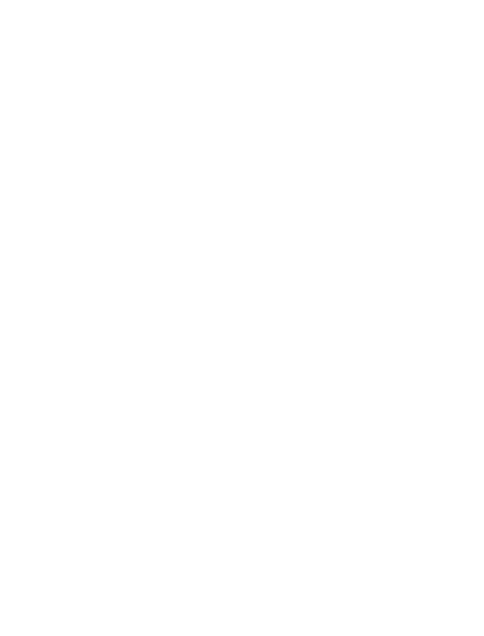

In [4]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

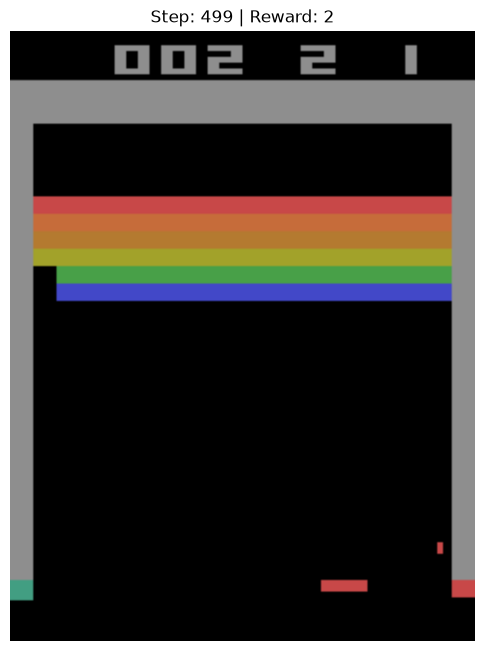

In [5]:
# Play game randomly
total_reward = 0

for step in range(500):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value)
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()

In [38]:
import numpy as np
import pandas as pd

In [39]:
np.random.seed(42)

In [40]:
n_trials = 1000
mean_score = 350
std_dev = 40
lower_bound = 310
upper_bound = 410

In [41]:
simulated_scores = np.random.normal(loc=mean_score, scale=std_dev, size=n_trials)

In [42]:
df_trials = pd.DataFrame({
    "trial_id": np.arange(1, n_trials + 1),
    "environment": "ALE/Breakout-v4",
    "score": np.round(simulated_scores, 2),
    "in_interval": (simulated_scores >= lower_bound) & (simulated_scores <= upper_bound)
})

In [43]:
df_trials["cumulative_mean_prob"] = df_trials["in_interval"].expanding().mean()

In [44]:
simulated_probability = df_trials["in_interval"].mean()
prob_std_dev = np.sqrt((simulated_probability * (1 - simulated_probability)) / n_trials)

In [45]:
n_simulations = 500

In [46]:
batch_scores = np.random.normal(loc=mean_score, scale=std_dev, size=(n_simulations, n_trials))

In [47]:
batch_probabilities = ((batch_scores >= lower_bound) & (batch_scores <= upper_bound)).mean(axis=1)

In [48]:
simulated_mean_probability = batch_probabilities.mean()
empirical_prob_std_dev = batch_probabilities.std(ddof=1)

In [49]:
print(f"Single-Run Simulated Probability:      {simulated_probability:.4f}")
print(f"Single-Run Probability Std Dev (SE):   {prob_std_dev:.4f}")
print(f"Simulated Mean Probability (500 runs): {simulated_mean_probability:.4f}")
print(f"Empirical Probability Std Dev:         {empirical_prob_std_dev:.4f}")

Single-Run Simulated Probability:      0.7780
Single-Run Probability Std Dev (SE):   0.0131
Simulated Mean Probability (500 runs): 0.7746
Empirical Probability Std Dev:         0.0132


In [50]:
df_trials.to_csv("breakout_v4_simulation_1000_trials.csv", index=False)

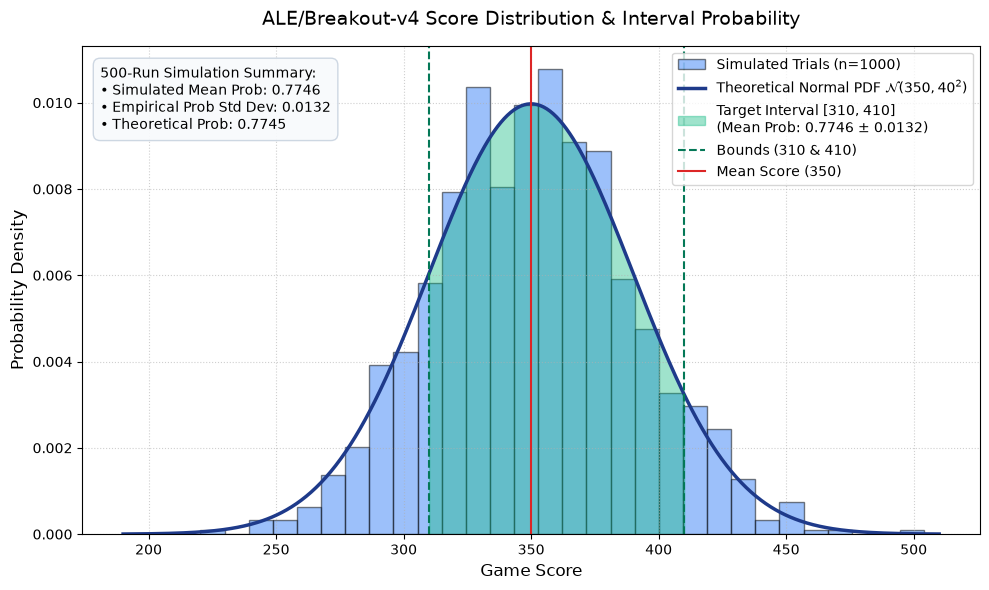

In [54]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Note: Uses df_trials['score'], simulated_mean_probability, and empirical_prob_std_dev from your earlier cells

plt.figure(figsize=(10, 6))

# Histogram of the original 1,000 simulated trial scores
count, bins, ignored = plt.hist(
    df_trials['score'], bins=30, density=True, alpha=0.5, color='#3B82F6', edgecolor='black', label='Simulated Trials (n=1000)'
)

# Theoretical Normal Curve PDF
x = np.linspace(mean_score - 4 * std_dev, mean_score + 4 * std_dev, 500)
pdf = stats.norm.pdf(x, mean_score, std_dev)
plt.plot(x, pdf, color='#1E3A8A', linewidth=2.5, label=f'Theoretical Normal PDF $\mathcal{{N}}({mean_score}, {std_dev}^2)$')

# Highlight the target interval [310, 410] with updated legend label
x_fill = np.linspace(lower_bound, upper_bound, 200)
y_fill = stats.norm.pdf(x_fill, mean_score, std_dev)
plt.fill_between(
    x_fill, y_fill, color='#10B981', alpha=0.4,
    label=f'Target Interval [310, 410]\n(Mean Prob: {simulated_mean_probability:.4f} ± {empirical_prob_std_dev:.4f})'
)

# Vertical threshold lines
plt.axvline(lower_bound, color='#047857', linestyle='--', linewidth=1.5, label='Bounds (310 & 410)')
plt.axvline(upper_bound, color='#047857', linestyle='--', linewidth=1.5)
plt.axvline(mean_score, color='#DC2626', linestyle='-', linewidth=1.5, label=f'Mean Score ({mean_score})')

# Add summary statistics text box in the upper-left corner of the plot
stats_text = (
    f"500-Run Simulation Summary:\n"
    f"• Simulated Mean Prob: {simulated_mean_probability:.4f}\n"
    f"• Empirical Prob Std Dev: {empirical_prob_std_dev:.4f}\n"
    f"• Theoretical Prob: 0.7745"
)
plt.gca().text(
    0.02, 0.96, stats_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8FAFC', edgecolor='#CBD5E1', alpha=0.95)
)

# Annotations & Formatting
plt.title('ALE/Breakout-v4 Score Distribution & Interval Probability', fontsize=14, pad=15)
plt.xlabel('Game Score', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.savefig('breakout_v4_normal_distribution.png', dpi=300)
plt.show()

# Conclusion

## The probability that an algorithm scores between 310 and 410 points in a random Breakout game is 0.774 both as a theoretical and empirical simulated probability. 
## This graph supports the answer as it shows the values of the theoretical and empirical probabilities calculated during the project and simulation. It also shows a shaded range of the values we are targeting in the question. 
## The results of the numerous trials of the simulation that are under the shaded range in the graph show the probability that this event is likely going to happen which supports my answer. 
## The graph also shows the STD of 0.0132 with the error bars(not shown in graph but if calculated) not exceeding the shaded range showing that 0.774 is the probability of this situation happening when a algorithm plays a raadom breakout game and gets a score betweeen 310 and 410.  